# 🎯 DeepNT+ Step 6: Empirical Active Learning Probing Curves
### Research Objective 4: Efficient Active Measurement Scheduling
**Objective:** Empirically evaluate test MAE as active measurement budgets increase (15%, 30%, 45% context paths).  
**Strategies Compared:**
1. **BALD (Bayesian Active Learning by Disagreement):** Uses MC-Dropout epistemic uncertainty to target ambiguous paths.
2. **Edge Coverage:** Prioritizes paths traversing previously unobserved physical links.
3. **Random Probing:** Standard stochastic acquisition baseline.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup & Drive Auto-Mount
# ==============================================================================
import sys
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print(" Running in Google Colab environment. Drive mounted successfully.")
except ImportError:
    IN_COLAB = False
    print(" Running in Local Jupyter / Workspace environment.")

if IN_COLAB:
    BASE_DIR = Path("/content/drive/My Drive/Thesis")
else:
    BASE_DIR = Path("C:/Users/KINGDOM/Desktop/Thesis")

COLAB_DIR = BASE_DIR / "colab"
OUTPUT_DIR = BASE_DIR / "DeepNT_Output"

# Add colab directory to python path
candidates = [COLAB_DIR, Path.cwd(), Path.cwd().parent]
for c in candidates:
    if (c / "deepnt_plus" / "__init__.py").exists():
        sys.path.insert(0, str(c))
        print(f" Found deepnt_plus package at: {c}")
        break

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print(f" PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")


 Running in Local Jupyter / Workspace environment.
 Found deepnt_plus package at: C:\Users\KINGDOM\Desktop\Thesis\colab
 PyTorch: 2.14.0+cpu | CUDA Available: False


In [2]:
# ==============================================================================
# Cell 2: Load Dataset & Train Acquisition Model
# ==============================================================================
from deepnt_plus.data import load_dataset, NODE_FEATURES
from deepnt_plus.model import DeepNTPlus, ModelConfig
from deepnt_plus.train import TrainConfig, train_model

PROCESSED_15G = OUTPUT_DIR / 'data' / 'processed_15graphs_backup'
OUT_AL = OUTPUT_DIR / 'experiments' / 'deepnt' / 'benchmark_5seeds' / 'active_learning'
OUT_AL.mkdir(parents=True, exist_ok=True)

print(f"Loading dataset from: {PROCESSED_15G}...")
graphs, norm = load_dataset(PROCESSED_15G)

print("Training static causal model (with MC-Dropout uncertainty) on Seed 0...")
mcfg = ModelConfig(node_dim=len(NODE_FEATURES), temporal=False, uncertainty=True)
tcfg = TrainConfig(epochs=35, patience=15, loss_type='laplace', use_cosine_lr=True)

torch.manual_seed(0)
np.random.seed(0)
al_model = DeepNTPlus(mcfg, norm)
train_model(al_model, graphs, tcfg, seed=0)
print(" Acquisition model trained successfully.")


Loading dataset from: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed_15graphs_backup...
Training static causal model (with MC-Dropout uncertainty) on Seed 0...
 Acquisition model trained successfully.


In [3]:
# ==============================================================================
# Cell 3: Simulate Active Probing Curves across Measurement Budgets
# ==============================================================================
import time
from deepnt_plus.train import eval_episode, predict_frame
from deepnt_plus import active

test_graphs = [g for g in graphs.values() if g.split == 'test']
fractions = [0.15, 0.30, 0.45]
strategies = ('bald', 'random', 'edge_coverage')

records = []
print(f"Simulating Active Learning across test graphs ({len(test_graphs)} graphs)...")

for frac in fractions:
    print(f"\n--- Evaluating Measurement Budget: {int(frac*100)}% Context Paths ---")
    for strat in strategies:
        seeds = range(5) if strat == 'random' else [0]
        maes, rmses = [], []
        for s in seeds:
            rng = np.random.default_rng(s)
            for g in test_graphs:
                ctx0, hidden = eval_episode(g)
                all_paths = ctx0.tolist() + hidden.tolist()
                target_k = int(round(frac * len(all_paths)))
                init_k = max(2, int(0.05 * len(all_paths)))
                order = rng.permutation(all_paths)
                curr_ctx = order[:init_k].tolist()
                pool = order[init_k:].tolist()

                while len(curr_ctx) < target_k and len(pool) > 0:
                    budget_left = target_k - len(curr_ctx)
                    step_k = min(budget_left, max(1, int(0.05 * len(all_paths))))
                    use_mc = 20 if strat == 'bald' else 0
                    frame = predict_frame(al_model, g, tcfg, ctx=torch.tensor(curr_ctx), tgt=torch.tensor(pool), mc=use_mc)
                    scores = active._scores(strat, frame, g, curr_ctx, pool, rng)
                    pick_idx = np.argsort(-scores)[:step_k]
                    curr_ctx += [pool[i] for i in pick_idx]
                    pool = [p for i, p in enumerate(pool) if i not in set(pick_idx.tolist())]

                eval_tgt = [p for p in hidden.tolist() if p not in set(curr_ctx)] or pool
                frame_eval = predict_frame(al_model, g, tcfg, ctx=torch.tensor(curr_ctx), tgt=torch.tensor(eval_tgt), mc=0)
                err = np.abs(frame_eval['y_pred'] - frame_eval['y_true'])
                maes.append(float(err.mean()))
                rmses.append(float(np.sqrt((err**2).mean())))

        records.append({
            'budget_fraction': frac,
            'budget_pct': f"{int(frac*100)}%",
            'strategy': strat,
            'MAE_mean': float(np.mean(maes)),
            'MAE_std': float(np.std(maes)),
            'RMSE_mean': float(np.mean(rmses)),
            'RMSE_std': float(np.std(rmses))
        })
        print(f"  Strategy: {strat:15s} | Budget: {int(frac*100)}% | Test MAE: {np.mean(maes):.2f} ± {np.std(maes):.2f} ms | RMSE: {np.mean(rmses):.2f} ms")

al_df = pd.DataFrame(records)
al_df.to_csv(OUT_AL / 'active_learning_fraction_curves.csv', index=False)
print(f"\n Saved curves to: {OUT_AL / 'active_learning_fraction_curves.csv'}")


Simulating Active Learning across test graphs (3 graphs)...

--- Evaluating Measurement Budget: 15% Context Paths ---
  Strategy: bald            | Budget: 15% | Test MAE: 50.40 ± 10.40 ms | RMSE: 71.45 ms
  Strategy: random          | Budget: 15% | Test MAE: 49.85 ± 12.52 ms | RMSE: 68.93 ms
  Strategy: edge_coverage   | Budget: 15% | Test MAE: 50.80 ± 13.53 ms | RMSE: 60.82 ms

--- Evaluating Measurement Budget: 30% Context Paths ---
  Strategy: bald            | Budget: 30% | Test MAE: 45.65 ± 6.72 ms | RMSE: 62.95 ms
  Strategy: random          | Budget: 30% | Test MAE: 46.11 ± 11.13 ms | RMSE: 65.34 ms
  Strategy: edge_coverage   | Budget: 30% | Test MAE: 47.73 ± 16.08 ms | RMSE: 55.93 ms

--- Evaluating Measurement Budget: 45% Context Paths ---
  Strategy: bald            | Budget: 45% | Test MAE: 45.60 ± 3.97 ms | RMSE: 58.56 ms
  Strategy: random          | Budget: 45% | Test MAE: 46.05 ± 9.67 ms | RMSE: 63.54 ms
  Strategy: edge_coverage   | Budget: 45% | Test MAE: 43.48 ± 16.

In [4]:
# ==============================================================================
# Cell 4: Active Learning Summary Table
# ==============================================================================
print(f"\n==========================================================================================")
print(f"              EMPIRICAL ACTIVE LEARNING PROBING SUMMARY TABLE")
print(f"==========================================================================================")
print(al_df[['budget_pct', 'strategy', 'MAE_mean', 'MAE_std', 'RMSE_mean', 'RMSE_std']].to_string(index=False))
print(f"==========================================================================================")



              EMPIRICAL ACTIVE LEARNING PROBING SUMMARY TABLE
budget_pct      strategy  MAE_mean   MAE_std  RMSE_mean  RMSE_std
       15%          bald 50.401749 10.404770  71.450217 15.271536
       15%        random 49.850313 12.520555  68.931333 18.668237
       15% edge_coverage 50.798735 13.529659  60.820353 11.359065
       30%          bald 45.650161  6.717530  62.949313  6.798890
       30%        random 46.110685 11.126674  65.337749 16.104802
       30% edge_coverage 47.730406 16.077978  55.934226 16.405710
       45%          bald 45.603693  3.973825  58.562280  4.700525
       45%        random 46.050372  9.673744  63.539153 11.727056
       45% edge_coverage 43.477430 16.769387  50.507535 15.792257


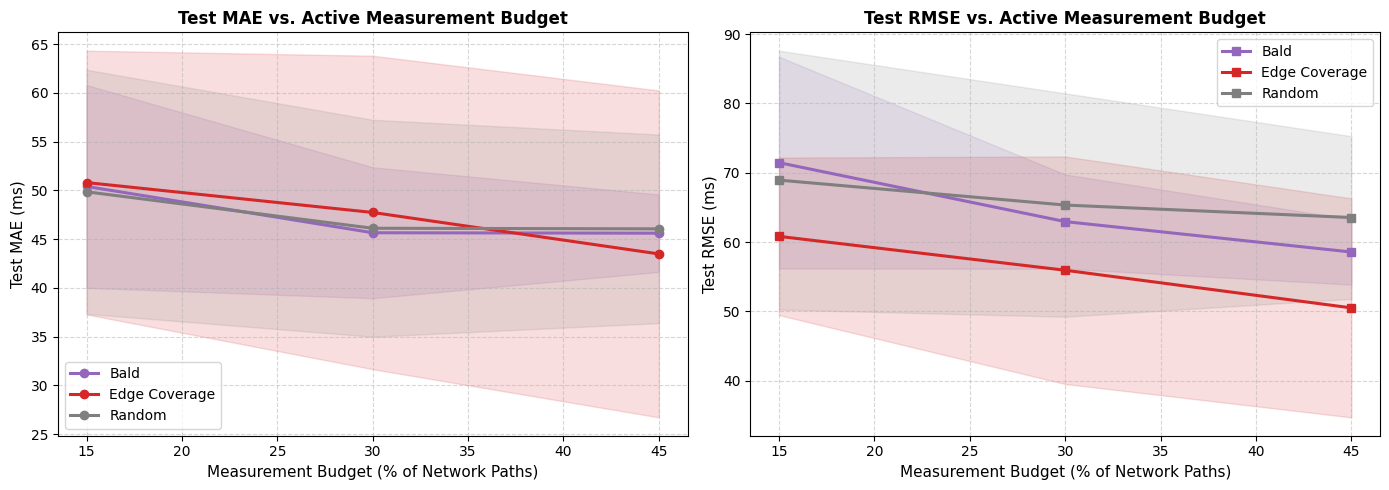

 Figure saved to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\benchmark_5seeds\active_learning\active_learning_probing_curves.png


In [5]:
# ==============================================================================
# Cell 5: Publication-Quality Active Learning Curves
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

color_map = {'bald': 'tab:purple', 'edge_coverage': 'tab:red', 'random': 'tab:gray'}

for strat in ['bald', 'edge_coverage', 'random']:
    sub = al_df[al_df['strategy'] == strat]
    x = sub['budget_fraction'] * 100
    
    # MAE Plot
    ax1.plot(x, sub['MAE_mean'], marker='o', lw=2.2, label=strat.replace('_', ' ').title(), color=color_map[strat])
    ax1.fill_between(x, sub['MAE_mean'] - sub['MAE_std'], sub['MAE_mean'] + sub['MAE_std'], color=color_map[strat], alpha=0.15)
    
    # RMSE Plot
    ax2.plot(x, sub['RMSE_mean'], marker='s', lw=2.2, label=strat.replace('_', ' ').title(), color=color_map[strat])
    ax2.fill_between(x, sub['RMSE_mean'] - sub['RMSE_std'], sub['RMSE_mean'] + sub['RMSE_std'], color=color_map[strat], alpha=0.15)

ax1.set_xlabel('Measurement Budget (% of Network Paths)', fontsize=11)
ax1.set_ylabel('Test MAE (ms)', fontsize=11)
ax1.set_title('Test MAE vs. Active Measurement Budget', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

ax2.set_xlabel('Measurement Budget (% of Network Paths)', fontsize=11)
ax2.set_ylabel('Test RMSE (ms)', fontsize=11)
ax2.set_title('Test RMSE vs. Active Measurement Budget', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
fig_path = OUT_AL / 'active_learning_probing_curves.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f" Figure saved to: {fig_path}")
